**Problem statement and Objective:** Airline operating margins are thin and volatile. This project identifies what drives operating margin, predicts whether an airline will be profitable in a given year, and forecasts industry revenue, using 2010–2026 data on 30 global airlines.

1. Explore and clean the dataset; classify variables and check data quality.
2. Compute descriptive statistics (mean, median, SD, etc.) across airlines, business models, and regions.
3. Run correlation analysis to find relationships with operating margin.
4. Build an OLS regression with feature selection to identify significant margin drivers.
5. Build logistic regression and decision tree models to classify profitability.
6. Compare linear vs. tree-based feature importance.
7. Forecast industry revenue using moving average, single, and double exponential smoothing.
8. Summarize key findings and business implications.

*Importing libraries*

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    roc_curve,
    classification_report
)

from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')


*importing dataset and dataset shape*

In [ ]:
df = pd.read_csv('airline_financials.csv')

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (497, 12)


,year,airline_name,iata_code,country_iso3,region,business_model,revenue_usd_bn,operating_margin_pct,operating_income_usd_bn,passengers_carried_m,load_factor_pct,fleet_size_est
0,2010,Delta Air Lines,DAL,USA,North America,legacy,32.09,3.4,1.09,48.1,84.5,160
1,2011,Delta Air Lines,DAL,USA,North America,legacy,34.54,1.1,0.39,51.8,80.4,172
2,2012,Delta Air Lines,DAL,USA,North America,legacy,35.50,5.2,1.85,53.2,83.0,177
3,2013,Delta Air Lines,DAL,USA,North America,legacy,36.20,8.2,2.97,54.3,84.6,181
4,2014,Delta Air Lines,DAL,USA,North America,legacy,39.00,8.8,3.44,58.5,83.9,194


*data cleaning*

In [ ]:
print(df.dtypes)


missing = df.isna().sum().sum()
print("\nTotal missing values:", missing)

duplicates = df.duplicated(['year', 'airline_name']).sum()
print("Duplicate airline-years:", duplicates)


calculated_income = (
    df['revenue_usd_bn'] *
    df['operating_margin_pct'] / 100
)

error = (calculated_income - df['operating_income_usd_bn']).abs().max()

print("Maximum operating income error:", round(error, 3))


zero_rows = df[
    (df['fleet_size_est'] == 0) |
    (df['passengers_carried_m'] == 0)
]

print("\nRows with zero fleet or passengers:")
print(zero_rows[
    ['year', 'airline_name',
     'revenue_usd_bn',
     'passengers_carried_m',
     'fleet_size_est']
])

# ---- FIX 1: drop the pre-launch Riyadh Air 2023 row (0 fleet, 0 passengers) so it does not distort statistics
df = df[df['fleet_size_est'] > 0].reset_index(drop=True)
print("\nRows after removing pre-launch row:", len(df))

# ---- Data insight: revenue per passenger is ~constant within a business model (passengers are redundant with revenue)
rev_per_pax = df['revenue_usd_bn'] * 1000 / df['passengers_carried_m']
print("\nRevenue per passenger ($) by business model:")
print(rev_per_pax.groupby(df['business_model']).agg(['mean', 'std']).round(1))

year                         int64
airline_name                object
iata_code                   object
country_iso3                object
region                      object
business_model              object
revenue_usd_bn             float64
operating_margin_pct       float64
operating_income_usd_bn    float64
passengers_carried_m       float64
load_factor_pct            float64
fleet_size_est               int64
dtype: object

Total missing values: 0
Duplicate airline-years: 0
Maximum operating income error: 0.026

Rows with zero fleet or passengers:
     year airline_name  revenue_usd_bn  passengers_carried_m  fleet_size_est
459  2023   Riyadh Air            0.01                   0.0               0

Rows after removing pre-launch row: 496

Revenue per passenger ($) by business model:
                 mean  std
business_model            
legacy          666.6  1.9
low_cost        250.0  1.1
regional        333.3  0.7


*data classification*

In [ ]:
classification = pd.DataFrame({
    'Variable': df.columns,

    'Type': [
        'Numeric - discrete',
        'Categorical',
        'Categorical',
        'Categorical',
        'Categorical',
        'Categorical',
        'Numeric - continuous',
        'Numeric - continuous',
        'Numeric - continuous',
        'Numeric - continuous',
        'Numeric - continuous',
        'Numeric - discrete'
    ],

    'Scale': [
        'Interval',
        'Nominal (ID)',
        'Nominal (ID)',
        'Nominal',
        'Nominal',
        'Nominal',
        'Ratio',
        'Ratio',
        'Ratio',
        'Ratio',
        'Ratio',
        'Ratio'
    ],

    'Role': [
        'Time index',
        'Entity ID',
        'Entity ID',
        'Feature',
        'Feature',
        'Feature',
        'Feature / TS target',
        'TARGET (regression)',
        'Excluded (leakage)',
        'Feature',
        'Feature',
        'Feature'
    ]
})

classification

,Variable,Type,Scale,Role
0,year,Numeric - discrete,Interval,Time index
1,airline_name,Categorical,Nominal (ID),Entity ID
2,iata_code,Categorical,Nominal (ID),Entity ID
3,country_iso3,Categorical,Nominal,Feature
4,region,Categorical,Nominal,Feature
5,business_model,Categorical,Nominal,Feature
6,revenue_usd_bn,Numeric - continuous,Ratio,Feature / TS target
7,operating_margin_pct,Numeric - continuous,Ratio,TARGET (regression)
8,operating_income_usd_bn,Numeric - continuous,Ratio,Excluded (leakage)
9,passengers_carried_m,Numeric - continuous,Ratio,Feature


*descriptive statistics*

In [ ]:
numeric_columns = [
    'revenue_usd_bn',
    'operating_margin_pct',
    'operating_income_usd_bn',
    'passengers_carried_m',
    'load_factor_pct',
    'fleet_size_est'
]


stats_table = df[numeric_columns].agg([
    'count',
    'mean',
    'median',
    'std',
    'var',
    'min',
    'max',
    'skew',
    'kurt'
]).T


stats_table['mode'] = [
    df[column].mode().iloc[0]
    for column in numeric_columns
]


stats_table['CV_%'] = (
    stats_table['std'] /
    stats_table['mean'] * 100
)

stats_table = stats_table.round(2)

stats_table

,count,mean,median,std,var,min,max,skew,kurt,mode,CV_%
revenue_usd_bn,496.0,15.75,11.67,12.98,168.43,0.39,68.38,1.43,1.81,1.59,82.41
operating_margin_pct,496.0,3.25,6.50,11.96,143.12,-44.10,17.70,-2.22,4.21,6.60,367.98
operating_income_usd_bn,496.0,0.73,0.73,1.54,2.36,-6.57,6.59,-0.80,4.58,0.60,209.46
passengers_carried_m,496.0,28.38,20.90,21.67,469.68,0.80,129.30,1.49,2.33,15.60,76.36
load_factor_pct,496.0,81.50,83.60,7.93,62.95,50.70,92.80,-2.39,5.50,83.50,9.73
fleet_size_est,496.0,78.23,58.00,64.90,4211.55,1.00,341.00,1.42,1.80,21.00,82.96


In [ ]:
business_summary = df.groupby('business_model').agg(
    number_of_rows=('year', 'size'),
    average_revenue=('revenue_usd_bn', 'mean'),
    average_margin=('operating_margin_pct', 'mean'),
    median_margin=('operating_margin_pct', 'median'),
    margin_std=('operating_margin_pct', 'std'),
    average_load_factor=('load_factor_pct', 'mean')
).round(2)

print("Business Model Summary:")
print(business_summary)

normal_period = df[~df['year'].isin([2020, 2021])]
covid_period = df[df['year'].isin([2020, 2021])]

print(
    "\nAverage margin excluding 2020-21:",
    round(normal_period['operating_margin_pct'].mean(), 2)
)

print(
    "Average margin during 2020-21:",
    round(covid_period['operating_margin_pct'].mean(), 2)
)

Business Model Summary:
                number_of_rows  average_revenue  average_margin  \
business_model                                                    
legacy                     360            18.94            2.08   
low_cost                   119             7.31            6.72   
regional                    17             7.24            3.71   

                median_margin  margin_std  average_load_factor  
business_model                                                  
legacy                    5.7       11.41                80.49  
low_cost                 11.3       12.85                84.20  
regional                  7.2       12.92                83.99  

Average margin excluding 2020-21: 7.21
Average margin during 2020-21: -26.64


In [ ]:
region_summary = df.groupby('region').agg(
    number_of_rows=('year', 'size'),
    average_margin=('operating_margin_pct', 'mean'),
    median_margin=('operating_margin_pct', 'median'),
    margin_std=('operating_margin_pct', 'std'),
    average_load_factor=('load_factor_pct', 'mean')
).round(2)

print("\nRegion Summary:")
print(region_summary)


Region Summary:
               number_of_rows  average_margin  median_margin  margin_std  \
region                                                                     
Asia                      170            3.12           6.30       11.82   
Europe                    119            3.26           6.50       11.83   
Latin America              34            5.13           8.45       12.32   
Middle East                71            1.71           5.50       12.12   
North America             102            3.91           7.15       12.23   

               average_load_factor  
region                              
Asia                         81.22  
Europe                       81.63  
Latin America                82.17  
Middle East                  80.65  
North America                82.19  


*data visualization*

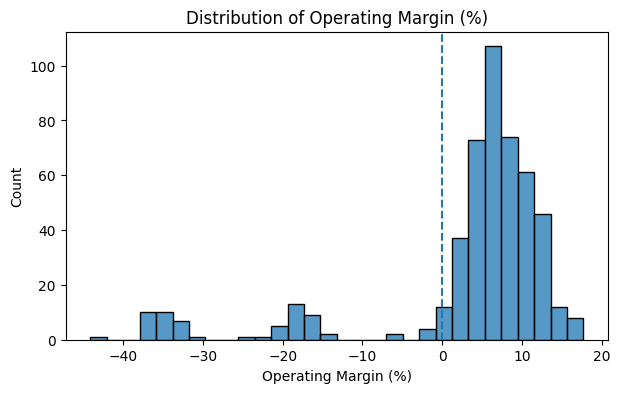

In [ ]:
plt.figure(figsize=(7, 4))

sns.histplot(
    df['operating_margin_pct'],
    bins=30
)

plt.axvline(0, linestyle='--')
plt.title('Distribution of Operating Margin (%)')
plt.xlabel('Operating Margin (%)')
plt.savefig('fig_hist_margin.png',dpi=150,bbox_inches='tight')
plt.show()

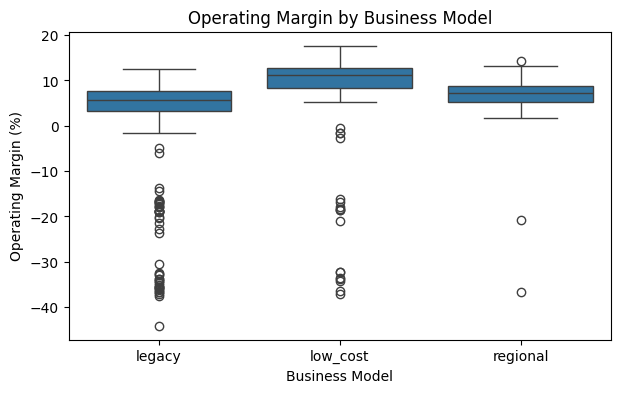

In [ ]:
plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df,
    x='business_model',
    y='operating_margin_pct'
)

plt.title('Operating Margin by Business Model')
plt.xlabel('Business Model')
plt.ylabel('Operating Margin (%)')
plt.savefig('fig_box_bm.png',dpi=150,bbox_inches='tight')
plt.show()

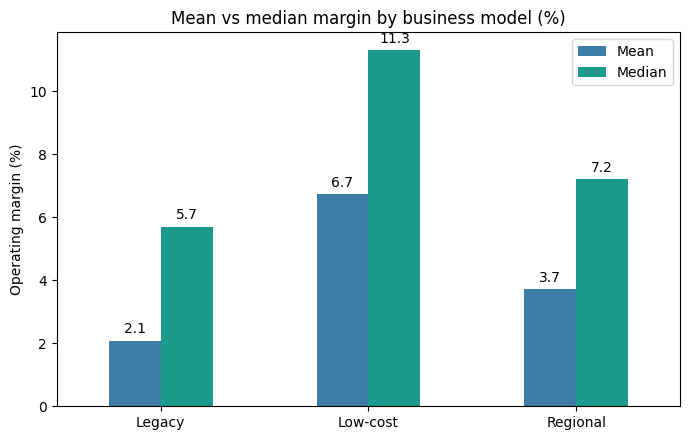

In [ ]:
bm = df.groupby('business_model')['operating_margin_pct'].agg(['mean', 'median'])
bm = bm.loc[['legacy', 'low_cost', 'regional']]          # fixed order
bm.index = ['Legacy', 'Low-cost', 'Regional']

ax = bm.plot(kind='bar', figsize=(7, 4.5), color=['#3D7EA6', '#1B998B'], rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)
plt.title('Mean vs median margin by business model (%)')
plt.xlabel('')
plt.ylabel('Operating margin (%)')
plt.legend(['Mean', 'Median'])
plt.tight_layout()
plt.show()

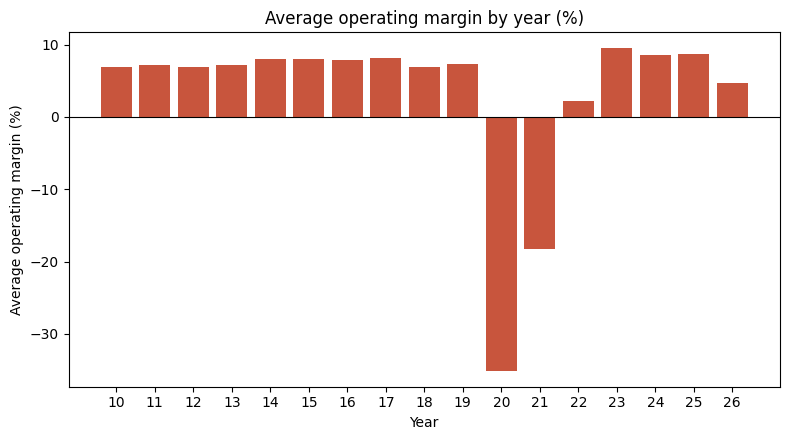

In [ ]:
yearly = df.groupby('year')['operating_margin_pct'].mean()

plt.figure(figsize=(8, 4.5))
plt.bar(yearly.index, yearly.values, color='#C8553D')
plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(yearly.index, [str(y)[2:] for y in yearly.index])   # 10, 11, ... 26
plt.title('Average operating margin by year (%)')
plt.xlabel('Year')
plt.ylabel('Average operating margin (%)')
plt.tight_layout()
plt.show()

*data visualization: correlation heatmap*

year                      -0.17
revenue_usd_bn             0.14
fleet_size_est             0.14
passengers_carried_m       0.23
operating_income_usd_bn    0.71
load_factor_pct            0.92
operating_margin_pct       1.00
Name: operating_margin_pct, dtype: float64


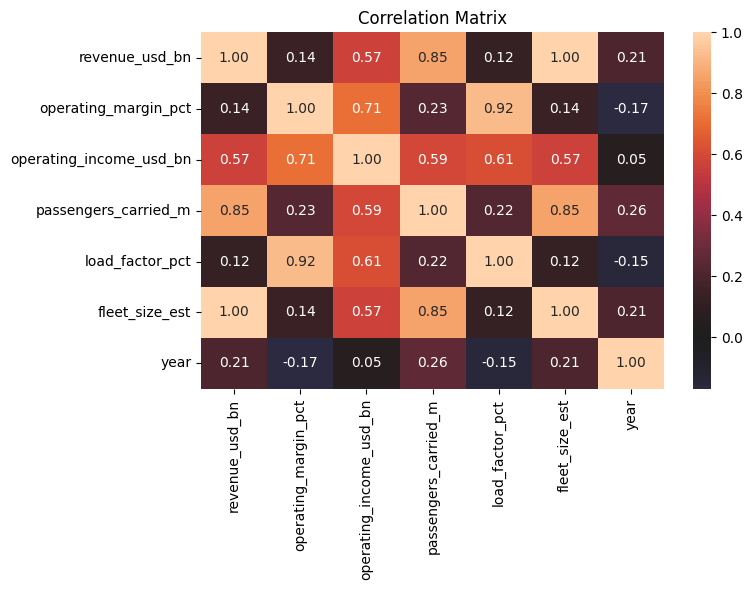


Correlation with operating margin:
                         All years  Excluding 2020-21
revenue_usd_bn                0.14              -0.16
operating_income_usd_bn       0.71               0.31
passengers_carried_m          0.23               0.06
load_factor_pct               0.92               0.37
fleet_size_est                0.14              -0.16
year                         -0.17              -0.04


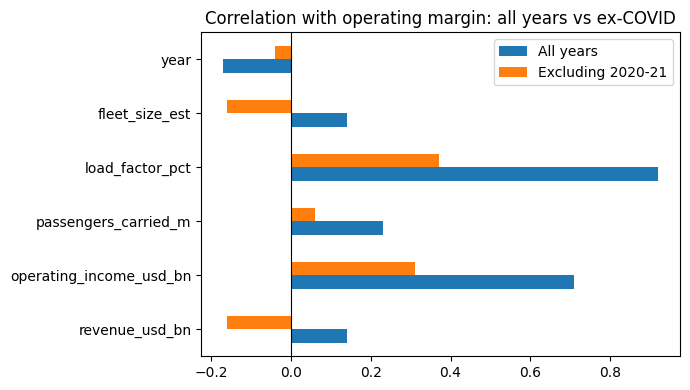

In [ ]:
numeric_columns = [
    'revenue_usd_bn',
    'operating_margin_pct',
    'operating_income_usd_bn',
    'passengers_carried_m',
    'load_factor_pct',
    'fleet_size_est',
    'year'
]

correlation = df[numeric_columns].corr().round(2)

print(
    correlation['operating_margin_pct']
    .sort_values()
)


plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    center=0
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.savefig('fig_corr_heatmap.png',dpi=150,bbox_inches='tight')
plt.show()

# ---- FIX 2: correlation is dominated by the 2020-21 COVID shock; compare with COVID years removed
ex = df[~df['year'].isin([2020, 2021])]
cmp_corr = pd.DataFrame({
    'All years': df[numeric_columns].corr()['operating_margin_pct'],
    'Excluding 2020-21': ex[numeric_columns].corr()['operating_margin_pct']
}).drop('operating_margin_pct').round(2)
print("\nCorrelation with operating margin:")
print(cmp_corr)
cmp_corr.plot(kind='barh', figsize=(7, 4)); plt.axvline(0, color='k', lw=.8)
plt.title('Correlation with operating margin: all years vs ex-COVID'); plt.tight_layout()
plt.savefig('fig_corr_compare.png', dpi=150, bbox_inches='tight'); plt.show()

*model data after and before removing multicollinearity (VIF)*

In [ ]:
model_data = df[df['fleet_size_est'] > 0].copy()

model_data['log_revenue'] = np.log(
    model_data['revenue_usd_bn']
)

model_data['rev_per_pax'] = (
    model_data['revenue_usd_bn'] * 1000 /
    model_data['passengers_carried_m']
)

model_data['pax_per_aircraft'] = (
    model_data['passengers_carried_m'] /
    model_data['fleet_size_est']
)


model_data['covid'] = model_data['year'].isin(
    [2020, 2021]
).astype(int)


model_data = model_data[
    np.isfinite(model_data['rev_per_pax'])
]



X = pd.get_dummies(
    model_data[
        [
            'load_factor_pct',
            'log_revenue',
            'rev_per_pax',
            'pax_per_aircraft',
            'covid',
            'business_model',
            'region'
        ]
    ],
    columns=['business_model', 'region'],
    drop_first=True
).astype(float)

y = model_data['operating_margin_pct']


X_with_constant = sm.add_constant(X)

vif = pd.Series(
    [
        variance_inflation_factor(
            X_with_constant.values, i
        )
        for i in range(1, X_with_constant.shape[1])
    ],
    index=X.columns
)

print("Initial VIF:")
print(vif.sort_values(ascending=False))



X = X.drop(columns=['rev_per_pax'])


X_with_constant = sm.add_constant(X)

vif = pd.Series(
    [
        variance_inflation_factor(
            X_with_constant.values, i
        )
        for i in range(1, X_with_constant.shape[1])
    ],
    index=X.columns
)

print("\nVIF after removing rev_per_pax:")
print(vif.sort_values(ascending=False))

Initial VIF:
rev_per_pax                12375.041385
business_model_low_cost    11650.270278
business_model_regional     1359.484152
pax_per_aircraft              42.756621
load_factor_pct                5.956526
covid                          5.638841
log_revenue                    3.171872
region_North America           2.269070
region_Europe                  1.426946
region_Middle East             1.313777
region_Latin America           1.209823
dtype: float64

VIF after removing rev_per_pax:
pax_per_aircraft           41.423976
business_model_low_cost    37.572999
load_factor_pct             5.942735
covid                       5.630949
business_model_regional     3.528608
log_revenue                 3.169610
region_North America        2.266698
region_Europe               1.426180
region_Middle East          1.292877
region_Latin America        1.209775
dtype: float64


*Test and train the dataset for OLS*

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

variables = list(X_train.columns)

while True:

    model = sm.OLS(
        y_train,
        sm.add_constant(X_train[variables])
    ).fit()

    p_values = model.pvalues.drop('const')


    if p_values.max() <= 0.05:
        break


    variable_to_remove = p_values.idxmax()
    variables.remove(variable_to_remove)


print("Variables retained:")
print(variables)

Variables retained:
['load_factor_pct', 'log_revenue', 'covid', 'business_model_low_cost', 'region_Latin America']


*OLS model summary*

In [ ]:
print("\nOLS Results:")
print(model.summary())


OLS Results:
                             OLS Regression Results                             
Dep. Variable:     operating_margin_pct   R-squared:                       0.895
Model:                              OLS   Adj. R-squared:                  0.894
Method:                   Least Squares   F-statistic:                     665.1
Date:                  Fri, 02 Oct 2026   Prob (F-statistic):          2.22e-188
Time:                          20:40:23   Log-Likelihood:                -1098.0
No. Observations:                   396   AIC:                             2208.
Df Residuals:                       390   BIC:                             2232.
Df Model:                             5                                         
Covariance Type:              nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------

*model metrics*

In [ ]:
predictions = model.predict(
    sm.add_constant(X_test[variables])
)


r2 = r2_score(y_test, predictions)

rmse = mean_squared_error(
    y_test,
    predictions
) ** 0.5

mae = mean_absolute_error(
    y_test,
    predictions
)

print("\nTest R²:", round(r2, 3))
print("Test RMSE:", round(rmse, 2))
print("Test MAE:", round(mae, 2))


Test R²: 0.911
Test RMSE: 3.57
Test MAE: 2.85


In [ ]:
# Standardize X and y
X_standard = (
    X_train[variables] -
    X_train[variables].mean()
) / X_train[variables].std()

y_standard = (
    y_train - y_train.mean()
) / y_train.std()


# Run standardized regression
standard_model = sm.OLS(
    y_standard,
    sm.add_constant(X_standard)
).fit()

standard_coefficients = (
    standard_model.params
    .drop('const')
    .sort_values()
)

print("Standardized coefficients:")
print(standard_coefficients.round(3))

Standardized coefficients:
covid                     -0.447
region_Latin America       0.034
log_revenue                0.048
business_model_low_cost    0.087
load_factor_pct            0.503
dtype: float64


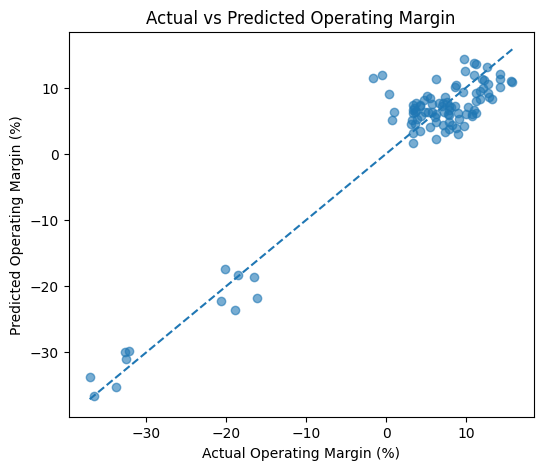

In [ ]:
plt.figure(figsize=(6, 5))

plt.scatter(
    y_test,
    predictions,
    alpha=0.6
)

minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--'
)

plt.xlabel('Actual Operating Margin (%)')
plt.ylabel('Predicted Operating Margin (%)')
plt.title('Actual vs Predicted Operating Margin')

plt.savefig('fig_actual_pred.png',dpi=150,bbox_inches='tight')
plt.show()

*regression assumption check: validation check*

In [ ]:
from statsmodels.stats.stattools import durbin_watson
from scipy import stats

residuals = model.resid

dw = durbin_watson(residuals)

skewness = stats.skew(residuals)

shapiro_p = stats.shapiro(residuals)[1]

print("Durbin-Watson:", round(dw, 2))
print("Residual skewness:", round(skewness, 2))
print("Shapiro-Wilk p-value:", round(shapiro_p, 3))

Durbin-Watson: 2.08
Residual skewness: -1.79
Shapiro-Wilk p-value: 0.0


*FIX 3: robustness of the OLS result - heteroscedasticity (HC3) and airline-clustered standard errors, plus final-model VIF*

In [ ]:
Xf = sm.add_constant(X_train[variables])
hc3 = sm.OLS(y_train, Xf).fit(cov_type='HC3')
groups = model_data.loc[X_train.index, 'airline_name']
clustered = sm.OLS(y_train, Xf).fit(cov_type='cluster', cov_kwds={'groups': groups})
robust = pd.DataFrame({'coef': model.params, 'p_OLS': model.pvalues,
                       'p_HC3': hc3.pvalues, 'p_clustered_by_airline': clustered.pvalues}).round(3)
print(robust)
print("\nFinal-model VIF:")
print(pd.Series([variance_inflation_factor(Xf.values, i) for i in range(1, Xf.shape[1])],
                index=variables).round(2))
for cols in (['covid'], ['load_factor_pct'], ['covid', 'load_factor_pct']):
    print(cols, "R2 =", round(sm.OLS(y_train, sm.add_constant(X_train[cols])).fit().rsquared, 3))

                           coef  p_OLS  p_HC3  p_clustered_by_airline
const                   -59.469  0.000  0.000                   0.000
load_factor_pct           0.766  0.000  0.000                   0.000
log_revenue               0.635  0.018  0.062                   0.036
covid                   -16.684  0.000  0.000                   0.000
business_model_low_cost   2.458  0.000  0.000                   0.000
region_Latin America      1.688  0.042  0.036                   0.000

Final-model VIF:
load_factor_pct            5.90
log_revenue                1.50
covid                      5.70
business_model_low_cost    1.60
region_Latin America       1.06
dtype: float64
['covid'] R2 = 0.822
['load_factor_pct'] R2 = 0.856
['covid', 'load_factor_pct'] R2 = 0.889


*FIX 4: ex-COVID model. The original re-added `pax_per_aircraft` (VIF ~ 41), which hid load factor's effect. Redone with the same backward elimination, without the collinear variable.*

In [ ]:
normal_data = model_data[model_data['covid'] == 0].copy()
X_normal = pd.get_dummies(
    normal_data[['load_factor_pct', 'log_revenue', 'business_model', 'region']],
    columns=['business_model', 'region'], drop_first=True).astype(float)
y_normal = normal_data['operating_margin_pct']

vars_n = list(X_normal.columns)
while True:
    normal_model = sm.OLS(y_normal, sm.add_constant(X_normal[vars_n])).fit()
    p = normal_model.pvalues.drop('const')
    if p.max() <= 0.05: break
    vars_n.remove(p.idxmax())

print("Non-COVID retained variables:", vars_n)
print("Non-COVID adjusted R2:", round(normal_model.rsquared_adj, 3))
print(normal_model.summary().tables[1])

Non-COVID retained variables: ['business_model_low_cost', 'business_model_regional']
Non-COVID adjusted R2: 0.278
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                       5.8808      0.200     29.336      0.000       5.487       6.275
business_model_low_cost     5.2354      0.402     13.012      0.000       4.445       6.026
business_model_regional     2.1392      0.945      2.265      0.024       0.283       3.996


*standard scaler to change features change features standardizes numeric features so they have a mean of 0 and a standard deviation of 1*

In [ ]:
model_data['profitable'] = (
    model_data['operating_margin_pct'] > 0
).astype(int)

print(
    model_data['profitable']
    .value_counts(normalize=True)
)


X_classification = X.copy()
y_classification = model_data['profitable']


X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_classification,
    y_classification,
    test_size=0.20,
    random_state=42,
    stratify=y_classification
)


# Standardize variables
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_c)
X_test_scaled = scaler.transform(X_test_c)


# Logistic regression
logistic_model = LogisticRegression(
    max_iter=2000
)

logistic_model.fit(
    X_train_scaled,
    y_train_c
)


# Predictions
class_predictions = logistic_model.predict(
    X_test_scaled
)

probabilities = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]


# Performance
accuracy = accuracy_score(
    y_test_c,
    class_predictions
)

auc = roc_auc_score(
    y_test_c,
    probabilities
)

print("Accuracy:", round(accuracy, 3))
print("AUC:", round(auc, 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_c, class_predictions))

print("\nClassification Report:")
print(
    classification_report(
        y_test_c,
        class_predictions
    )
)


profitable
1    0.858871
0    0.141129
Name: proportion, dtype: float64
Accuracy: 0.99
AUC: 0.935

Confusion Matrix:
[[13  1]
 [ 0 86]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.93      0.96        14
           1       0.99      1.00      0.99        86

    accuracy                           0.99       100
   macro avg       0.99      0.96      0.98       100
weighted avg       0.99      0.99      0.99       100



*FIX 5: COVID perfectly separates the classes (no airline was profitable in 2020-21), so the unpenalised odds ratio is infinite and sklearn's L2-shrunk 0.13 is an artefact. Added baselines, cross-validation and an ex-COVID logistic model with p-values.*

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

print("Profitable share in COVID years  :", model_data.loc[model_data.covid == 1, 'profitable'].mean())
print("Profitable share in other years  :", round(model_data.loc[model_data.covid == 0, 'profitable'].mean(), 3))
print("Majority-class baseline accuracy :", round(y_classification.mean(), 3))
print("Rule 'profitable if not COVID'   :", round(accuracy_score(y_classification, 1 - model_data['covid']), 3))

cv = StratifiedKFold(5, shuffle=True, random_state=42)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
print("5-fold CV accuracy:", cross_val_score(pipe, X_classification, y_classification, cv=cv).mean().round(3))
print("5-fold CV AUC     :", cross_val_score(pipe, X_classification, y_classification, cv=cv, scoring='roc_auc').mean().round(3))

# Logit on non-COVID years (statsmodels, p-values)
nc = model_data['covid'] == 0
Xl = X_classification.loc[nc].drop(columns=['covid', 'pax_per_aircraft'])
Xl = (Xl - Xl.mean()) / Xl.std()
logit_nc = sm.Logit(y_classification[nc], sm.add_constant(Xl.loc[:, Xl.std() > 0])).fit(disp=0)
print("\nNon-COVID logit (standardised features): n =", int(nc.sum()), "unprofitable =", int((y_classification[nc] == 0).sum()))
print(pd.DataFrame({'odds_ratio': np.exp(logit_nc.params), 'p_value': logit_nc.pvalues}).round(3))

Profitable share in COVID years  : 0.0
Profitable share in other years  : 0.973
Majority-class baseline accuracy : 0.859
Rule 'profitable if not COVID'   : 0.976
5-fold CV accuracy: 0.976
5-fold CV AUC     : 0.931

Non-COVID logit (standardised features): n = 438 unprofitable = 12
                         odds_ratio  p_value
const                        99.751    0.999
load_factor_pct               0.923    0.849
log_revenue                   1.948    0.070
business_model_low_cost       1.237    0.656
business_model_regional      58.961    1.000
region_Europe                 0.465    0.034
region_Latin America          0.914    0.784
region_Middle East            0.785    0.522
region_North America          0.730    0.560


*odds ratio*

In [ ]:
odds_ratio = pd.Series(
    np.exp(logistic_model.coef_[0]),
    index=X.columns
)

print("\nOdds ratios:")
print(odds_ratio.sort_values(ascending=False).round(2))


Odds ratios:
log_revenue                1.97
load_factor_pct            1.94
region_North America       1.24
pax_per_aircraft           1.19
business_model_regional    1.07
region_Latin America       0.97
region_Middle East         0.81
business_model_low_cost    0.80
region_Europe              0.51
covid                      0.13
dtype: float64


*decision tree regression*

In [ ]:
regression_tree = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=8,
    random_state=42
)

regression_tree.fit(
    X_train,
    y_train
)

tree_predictions = regression_tree.predict(X_test)

tree_r2 = r2_score(
    y_test,
    tree_predictions
)

tree_rmse = mean_squared_error(
    y_test,
    tree_predictions
) ** 0.5

print("Regression Tree R²:", round(tree_r2, 3))
print("Regression Tree RMSE:", round(tree_rmse, 2))


Regression Tree R²: 0.91
Regression Tree RMSE: 3.59


In [ ]:
importance = pd.Series(
    regression_tree.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nRegression Tree Feature Importance:")
print(importance.head(8).round(3))


Regression Tree Feature Importance:
covid                      0.888
load_factor_pct            0.067
business_model_low_cost    0.035
log_revenue                0.009
pax_per_aircraft           0.001
business_model_regional    0.000
region_Europe              0.000
region_Latin America       0.000
dtype: float64


In [ ]:
classification_tree = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=10,
    random_state=42
)

classification_tree.fit(
    X_train_c,
    y_train_c
)

tree_class_predictions = classification_tree.predict(
    X_test_c
)

tree_accuracy = accuracy_score(
    y_test_c,
    tree_class_predictions
)

tree_auc = roc_auc_score(
    y_test_c,
    classification_tree.predict_proba(X_test_c)[:, 1]
)

print("\nClassification Tree Accuracy:",
      round(tree_accuracy, 3))

print("Classification Tree AUC:",
      round(tree_auc, 3))


Classification Tree Accuracy: 0.99
Classification Tree AUC: 0.944


In [ ]:
classification_importance = pd.Series(
    classification_tree.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nClassification Tree Feature Importance:")
print(classification_importance.head(5).round(3))


Classification Tree Feature Importance:
covid                      0.985
pax_per_aircraft           0.008
log_revenue                0.006
load_factor_pct            0.001
business_model_low_cost    0.000
dtype: float64


*Decision tree plot and linear vs tree feature-importance comparison*

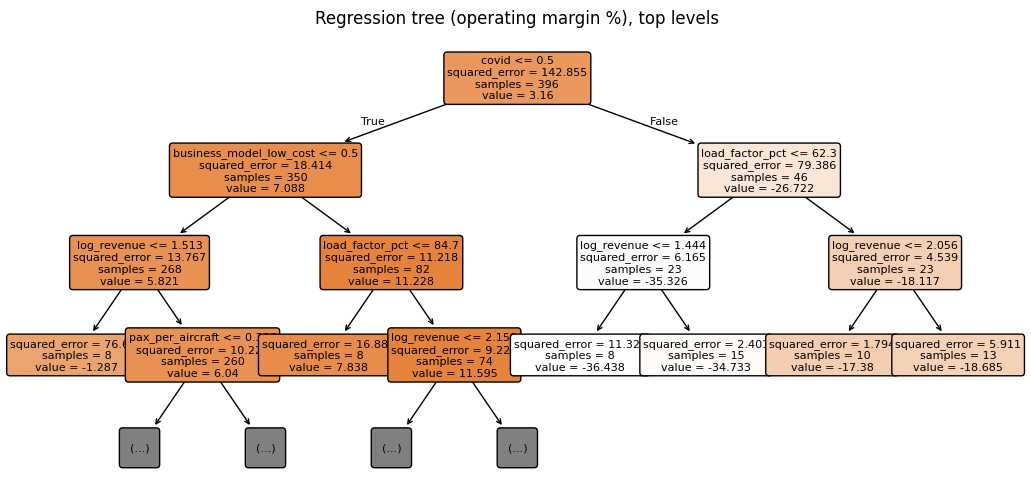

                         OLS (|std coef|, share)  Regression tree  \
covid                                      0.400            0.888   
load_factor_pct                            0.449            0.067   
business_model_low_cost                    0.078            0.035   
log_revenue                                0.043            0.009   
pax_per_aircraft                           0.000            0.001   
business_model_regional                    0.000            0.000   
region_Europe                              0.000            0.000   
region_Latin America                       0.031            0.000   
region_Middle East                         0.000            0.000   
region_North America                       0.000            0.000   

                         Classification tree  
covid                                  0.985  
load_factor_pct                        0.001  
business_model_low_cost                0.000  
log_revenue                            0.006  
pax_p

In [ ]:
plt.figure(figsize=(13, 6))
plot_tree(regression_tree, feature_names=list(X.columns), filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title('Regression tree (operating margin %), top levels')
plt.savefig('fig_tree.png', dpi=150, bbox_inches='tight'); plt.show()

abs_std = standard_coefficients.abs().reindex(X.columns).fillna(0)
comparison = pd.DataFrame({
    'OLS (|std coef|, share)': abs_std / abs_std.sum(),
    'Regression tree': regression_tree.feature_importances_,
    'Classification tree': classification_tree.feature_importances_
}, index=X.columns).round(3).sort_values('Regression tree', ascending=False)
print(comparison)

*time series*

*Time series. FIX 6: cells re-ordered so the notebook runs top to bottom; industry revenue uses the 29 airlines with full 2010-2026 history (constant composition); added fitted smoothing parameters and an ex-shock error comparison.*

In [ ]:
full_history = df.groupby('airline_name')['year'].nunique().loc[lambda s: s == s.max()].index
time_series = df[df['airline_name'].isin(full_history)].groupby('year')['revenue_usd_bn'].sum()
time_series.index = pd.to_datetime(time_series.index, format='%Y')
time_series = time_series.asfreq('YS')
print("Airlines in series:", len(full_history))
print(time_series.round(1))

# Models
moving_average = time_series.rolling(3).mean().shift(1)                      # MA(3) one-step forecast
ses_model  = SimpleExpSmoothing(time_series, initialization_method='estimated').fit()
holt_model = Holt(time_series, initialization_method='estimated').fit()      # double exponential smoothing
ses_fitted, holt_fitted = ses_model.fittedvalues, holt_model.fittedvalues
print("\nSES  alpha =", round(ses_model.params['smoothing_level'], 3))
print("Holt alpha =", round(holt_model.params['smoothing_level'], 3),
      " beta =", round(holt_model.params['smoothing_trend'], 3),
      " trend/yr =", round(holt_model.params['initial_trend'], 1))

# Forecasts 2027-2029
future_years = [2027, 2028, 2029]
moving_average_forecast = [time_series.iloc[-3:].mean()] * 3
ses_forecast  = ses_model.forecast(3)
holt_forecast = holt_model.forecast(3)

# Accuracy
test_years = time_series.index[3:]
calm_years = [y for y in test_years if y.year not in (2020, 2021, 2022)]
def calculate_errors(actual, forecast, yrs):
    e = actual[yrs] - forecast[yrs]
    return [round(e.abs().mean(), 2), round((e ** 2).mean() ** .5, 2), round((e.abs() / actual[yrs]).mean() * 100, 2)]
results = pd.DataFrame({
    'MA(3) all': calculate_errors(time_series, moving_average, test_years),
    'SES all':   calculate_errors(time_series, ses_fitted, test_years),
    'Holt all':  calculate_errors(time_series, holt_fitted, test_years),
    'MA(3) ex-2020-22': calculate_errors(time_series, moving_average, calm_years),
    'SES ex-2020-22':   calculate_errors(time_series, ses_fitted, calm_years),
    'Holt ex-2020-22':  calculate_errors(time_series, holt_fitted, calm_years)},
    index=['MAE', 'RMSE', 'MAPE %'])
print("\nForecast accuracy:"); print(results)
forecast_table = pd.DataFrame({'Year': future_years, 'MA(3)': moving_average_forecast,
                               'SES': ses_forecast.values, 'Holt': holt_forecast.values})
print("\nForecasts:"); print(forecast_table.round(1))

Airlines in series: 29
year
2010-01-01    317.7
2011-01-01    344.3
2012-01-01    371.9
2013-01-01    393.9
2014-01-01    422.2
2015-01-01    444.5
2016-01-01    472.3
2017-01-01    485.3
2018-01-01    510.4
2019-01-01    519.2
2020-01-01    204.5
2021-01-01    288.6
2022-01-01    476.1
2023-01-01    585.1
2024-01-01    611.4
2025-01-01    659.2
2026-01-01    699.7
Freq: YS-JAN, Name: revenue_usd_bn, dtype: float64

SES  alpha = 1.0
Holt alpha = 1.0  beta = 0.0  trend/yr = 23.9

Forecast accuracy:
        MA(3) all  SES all  Holt all  MA(3) ex-2020-22  SES ex-2020-22  \
MAE        105.86    68.37     52.11             83.65           33.72   
RMSE       133.83   107.30    104.72            107.09           42.57   
MAPE %      27.56    20.78     17.85             15.20            6.22   

        Holt ex-2020-22  
MAE               15.20  
RMSE              27.79  
MAPE %             2.64  

Forecasts:
   Year  MA(3)    SES   Holt
0  2027  656.8  699.7  723.6
1  2028  656.8  699.7  747

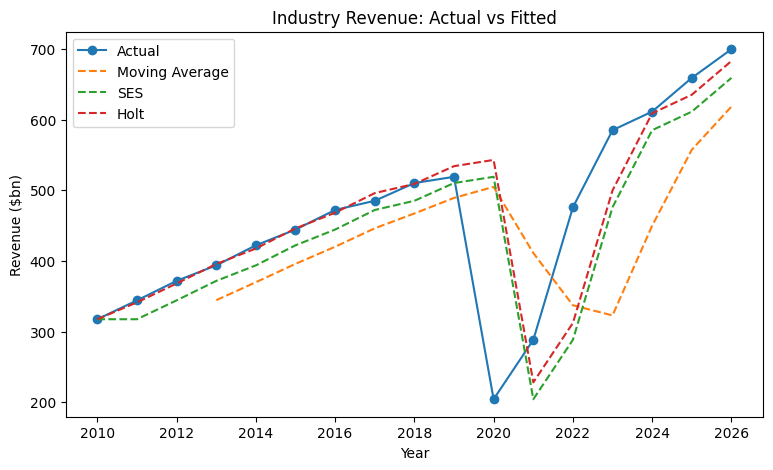

In [ ]:
years = time_series.index


# Historical revenue and fitted values
plt.figure(figsize=(9, 5))

plt.plot(
    years,
    time_series,
    'o-',
    label='Actual'
)

plt.plot(
    years,
    moving_average,
    '--',
    label='Moving Average'
)

plt.plot(
    years,
    ses_fitted,
    '--',
    label='SES'
)

plt.plot(
    years,
    holt_fitted,
    '--',
    label='Holt'
)

plt.title('Industry Revenue: Actual vs Fitted')
plt.xlabel('Year')
plt.ylabel('Revenue ($bn)')
plt.legend()

plt.savefig('fig_ts_fit.png',dpi=150,bbox_inches='tight')
plt.show()

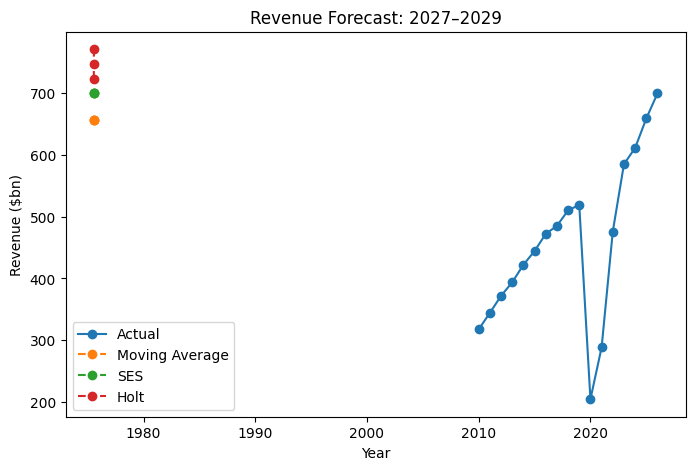

In [ ]:
# Forecast plot
plt.figure(figsize=(8, 5))

plt.plot(
    years,
    time_series,
    'o-',
    label='Actual'
)

plt.plot(
    future_years,
    moving_average_forecast,
    'o--',
    label='Moving Average'
)

plt.plot(
    future_years,
    ses_forecast.values,
    'o--',
    label='SES'
)

plt.plot(
    future_years,
    holt_forecast.values,
    'o--',
    label='Holt'
)

plt.title('Revenue Forecast: 2027–2029')
plt.xlabel('Year')
plt.ylabel('Revenue ($bn)')
plt.legend()

plt.savefig('fig_ts_forecast.png',dpi=150,bbox_inches='tight')
plt.show()